<a href="https://colab.research.google.com/github/ancestor9/Scikit-learn-model-selection-evaluation/blob/main/seminar_note_1_1_getting_started.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Getting started

In [1]:
from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = 'all'
import warnings
warnings.filterwarnings(action='ignore')

In [2]:
import seaborn as sns
import matplotlib.pyplot as plt
get_ipython().run_line_magic('matplotlib', 'inline')
import pandas as pd
import numpy as np

In [3]:
from sklearn import datasets
X, y = datasets.load_wine(return_X_y=True, as_frame=True)
df = X.merge(y, left_index=True, right_index=True)
df.head()
df.shape

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


(178, 14)

In [4]:
df.target.value_counts(normalize=True)

,proportion
target,
1,0.398876
0,0.331461
2,0.269663


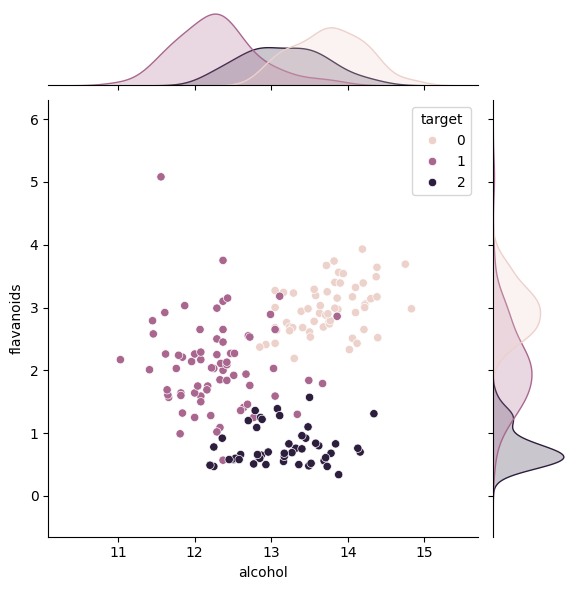

In [5]:
sns.jointplot(data=df, x='alcohol',y='flavanoids', hue='target')

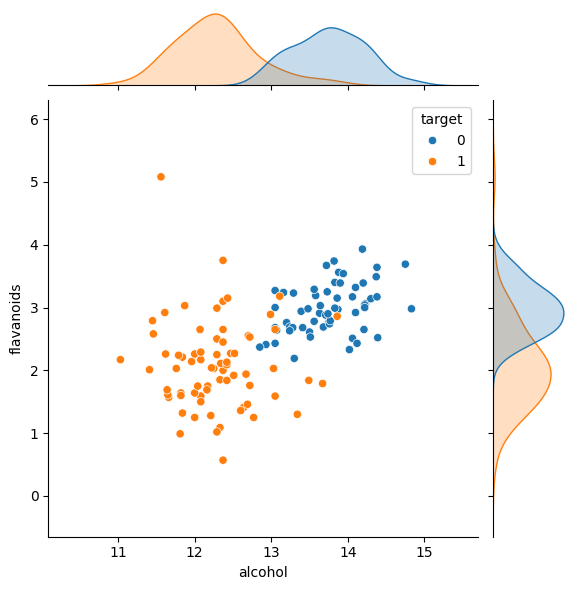

In [6]:
sns.jointplot(data=df.loc[df.target < 2, :], x='alcohol',y='flavanoids', hue='target')

In [7]:
data = df.loc[df.target < 2, :]
data_mean = data.groupby('target')[['alcohol','flavanoids']].mean().round(2).reset_index()
data_mean

,target,alcohol,flavanoids
0,0,13.74,2.98
1,1,12.28,2.08


In [8]:
X = data_mean.drop(['target'], axis=1)
X

,alcohol,flavanoids
0,13.74,2.98
1,12.28,2.08


In [9]:
y = data_mean['target']
y

,target
0,0
1,1


In [10]:
from sklearn.ensemble import RandomForestClassifier
clf = RandomForestClassifier(random_state=0)
clf.fit(X, y)
clf.predict([[14, 3]])
clf.predict_proba([[14, 3]])

clf.predict([[11, 1]])
clf.predict_proba([[11, 1]])

# X에 대한 예측값을 새로 정의하여 y와 길이를 맞춰줍니다.
y_pred = clf.predict(X)
(y_pred == y).mean()
from sklearn.metrics import accuracy_score # 사이킷런의 정확도 산출 모듈
accuracy_score(y_pred, y)

RandomForestClassifier(random_state=0)

array([0])

array([[0.7, 0.3]])

array([1])

array([[0.22, 0.78]])

np.float64(1.0)

1.0

In [11]:
X = data[['alcohol','flavanoids']]
y = data['target']
y_pred = clf.predict(X)
(y_pred == y).mean()
from sklearn.metrics import accuracy_score # 사이킷런의 정확도 산출 모듈
accuracy_score(y_pred, y)

np.float64(0.9230769230769231)

0.9230769230769231

In [12]:
clf = RandomForestClassifier(random_state=0)
clf.fit(X,y)

y_pred = clf.predict(X)
accuracy_score(y_pred, y)

RandomForestClassifier(random_state=0)

1.0

In [13]:
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from mlxtend.plotting import plot_decision_regions # 2차원 특성변수의 분류경계선을 시각
clfs = [RandomForestClassifier(), LogisticRegression(), SVC(), GaussianNB(), KNeighborsClassifier()]

In [14]:
for i, clf in enumerate(clfs) :
    y_pred = clf.fit(X,y).predict(X)
    accuracy = accuracy_score(y_pred, y)
    print(f'{clf}알고리즘의 예측 모형정확도 {round(accuracy, 2)}') # 정확도(Accuracy)

RandomForestClassifier()알고리즘의 예측 모형정확도 1.0
LogisticRegression()알고리즘의 예측 모형정확도 0.93
SVC()알고리즘의 예측 모형정확도 0.93
GaussianNB()알고리즘의 예측 모형정확도 0.94
KNeighborsClassifier()알고리즘의 예측 모형정확도 0.96


## 새로운 데이터를 불러와서 예시로 보여준다

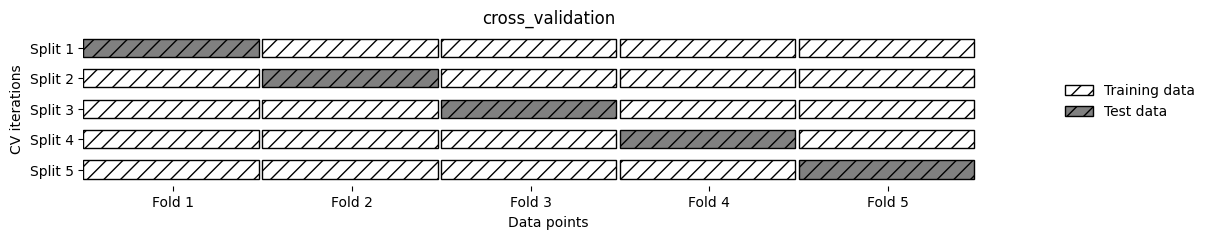

In [15]:
!pip install mglearn
import mglearn
mglearn.plots.plot_cross_validation()

In [16]:
X_train = X[1::2]; y_train = y[1::2]
X_test = X[::2]; y_test = y[::2]

X_train.head()
X_test.head()

,alcohol,flavanoids
1,13.20,2.76
3,14.37,3.49
5,14.20,3.39
7,14.06,2.51
9,13.86,3.15


,alcohol,flavanoids
0,14.23,3.06
2,13.16,3.24
4,13.24,2.69
6,14.39,2.52
8,14.83,2.98


In [17]:
clf = LogisticRegression()
y_pred = clf.fit(X_train, y_train).predict(X_test)
accuracy_score(y_pred, y_test)

0.9538461538461539

In [18]:
X_train

,alcohol,flavanoids
1,13.20,2.76
3,14.37,3.49
5,14.20,3.39
7,14.06,2.51
9,13.86,3.15
...,...,...
121,11.56,5.08
123,13.05,2.65
125,12.07,2.65
127,11.79,2.24


In [19]:
from sklearn.model_selection import train_test_split # 훈련과 검증데이터 분류
X_train, X_test, y_train, y_test = train_test_split(X, y,
                                                    test_size = 0.2,
                                                    random_state = 0)
y_pred = clf.fit(X_train, y_train).predict(X_test)
accuracy_score(y_pred, y_test)

0.9615384615384616

In [20]:
clf

LogisticRegression()

In [21]:
from sklearn.preprocessing import StandardScaler
X_train_std = StandardScaler().fit(X_train).transform(X_train)
X_test_std = StandardScaler().fit(X_test).transform(X_test)
y_pred= clf.fit(X_train_std, y_train).predict(X_test_std)
accuracy_score(y_pred, y_test)

0.9230769230769231

In [22]:
from sklearn.pipeline import make_pipeline
X_train, X_test, y_train, y_test = train_test_split(X, y, stratify=y, random_state=0)
pipe = make_pipeline(
    StandardScaler(),
    LogisticRegression()
)
y_pred = pipe.fit(X_train, y_train).predict(X_test)
accuracy_score(y_pred, y_test)

0.9393939393939394

In [23]:
from sklearn.pipeline import Pipeline
steps = [('scaler', StandardScaler()), ('SVM', SVC())]
pipeline = Pipeline(steps) # define the pipeline object.
y_pred = pipeline.fit(X_train, y_train).predict(X_test)
accuracy_score(y_pred, y_test)

0.9393939393939394

In [24]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
classifiers = [
    LogisticRegression(),
    KNeighborsClassifier(5),
    RandomForestClassifier()]

In [25]:
for clf in classifiers:
    clf
    pipe = make_pipeline(
    StandardScaler(),
    clf)
    y_pred = pipe.fit(X_train, y_train).predict(X_test)
    accuracy_score(y_pred, y_test)
    print('*'*100)

LogisticRegression()

0.9393939393939394

****************************************************************************************************


KNeighborsClassifier()

0.9393939393939394

****************************************************************************************************


RandomForestClassifier()

0.9393939393939394

****************************************************************************************************


<BarContainer object of 5 artists>

Text(0.5, 1.0, '5-KFlod, Model Accuracy')

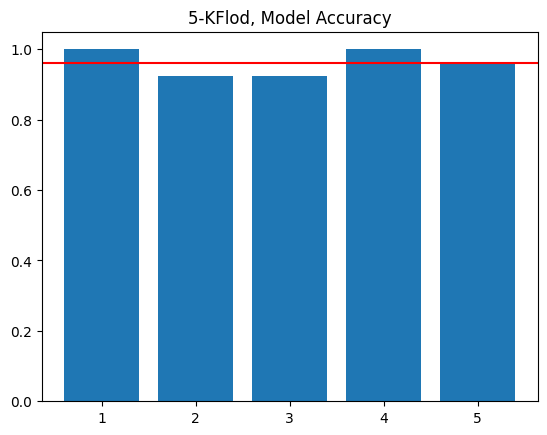

In [26]:
from sklearn.model_selection import KFold
kf = KFold(n_splits=5, shuffle=True, random_state=11)
accuracy_list = []
for train_index, test_index in kf.split(X):
    X_train, y_train = X.iloc[train_index, :], y[train_index]
    X_test, y_test = X.iloc[test_index], y[test_index]
    y_predict = pipe.fit(X_train, y_train).predict(X_test)
    accuracy_list.append(accuracy_score(y_test, y_predict))

plt.bar(np.arange(1, 6), accuracy_list)
plt.axhline(y=np.array(accuracy_list).mean(), color='r', linestyle='-')
plt.title('5-KFlod, Model Accuracy')

In [34]:
accuracy_list

[1.0, 0.9230769230769231, 0.9230769230769231, 1.0, 0.9615384615384616]

In [27]:
from sklearn.model_selection import cross_validate
np.mean(accuracy_list)
result = cross_validate(pipe, X, y, cv=kf)  # defaults to 5-fold CV
result['test_score'].mean()

np.float64(0.9615384615384615)

np.float64(0.9615384615384617)

In [28]:
pipe
clf
clf.get_params()

Pipeline(steps=[('standardscaler', StandardScaler()),
                ('randomforestclassifier', RandomForestClassifier())])

RandomForestClassifier()

{'bootstrap': True,
 'ccp_alpha': 0.0,
 'class_weight': None,
 'criterion': 'gini',
 'max_depth': None,
 'max_features': 'sqrt',
 'max_leaf_nodes': None,
 'max_samples': None,
 'min_impurity_decrease': 0.0,
 'min_samples_leaf': 1,
 'min_samples_split': 2,
 'min_weight_fraction_leaf': 0.0,
 'monotonic_cst': None,
 'n_estimators': 100,
 'n_jobs': None,
 'oob_score': False,
 'random_state': None,
 'verbose': 0,
 'warm_start': False}

In [29]:
pipe = make_pipeline(
    StandardScaler(),
    RandomForestClassifier()
)

In [30]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint
param_distributions = {'randomforestclassifier__max_depth': np.random.choice(100, 50),
                       'randomforestclassifier__n_estimators' : np.random.choice(100, 50)
                      }
rs = RandomizedSearchCV(estimator=pipe,
                        n_iter=20,
                        param_distributions=param_distributions,
                        random_state=0, verbose=1)
rs.fit(X_train, y_train)

Fitting 5 folds for each of 20 candidates, totalling 100 fits


RandomizedSearchCV(estimator=Pipeline(steps=[('standardscaler',
                                              StandardScaler()),
                                             ('randomforestclassifier',
                                              RandomForestClassifier())]),
                   n_iter=20,
                   param_distributions={'randomforestclassifier__max_depth': array([38, 21, 90, 48, 73, 55, 97, 42, 56, 74, 59, 82,  6,  0, 91, 96, 87,
       25, 76, 26, 84,  5,  6, 98, 22, 38, 22, 35, 12, 51, 26,  2,  2, 53,
       50, 98, 10, 39, 87, 80,  6, 66, 49, 90, 67, 18, 12, 64, 24, 94]),
                                        'randomforestclassifier__n_estimators': array([93,  3, 98, 17, 79, 76, 78, 99, 43, 22, 58, 46, 81, 75, 84, 42, 74,
       50, 88, 68, 89,  5, 75, 85, 64, 53, 61, 86, 50, 97, 48, 62, 77, 82,
        3, 76, 74, 32, 64, 49, 45, 14,  6, 67, 29, 86, 58, 16, 30, 33])},
                   random_state=0, verbose=1)

In [31]:
print(f'optimal train score: {:.3f}'.format(rs.best_score_))
print('test score: {:.3f}'.format(rs.score(X_test, y_test)))
print('optimal parameter: {}'.format(rs.best_params_))

optimal train score: 0.933
test score: 0.962
optimal parameter: {'randomforestclassifier__n_estimators': np.int64(17), 'randomforestclassifier__max_depth': np.int64(53)}


In [32]:
results= pd.DataFrame(rs.cv_results_)[['params','mean_test_score', 'rank_test_score']]
results.sort_values('rank_test_score').round(4).head(10)

,params,mean_test_score,rank_test_score
0,"{'randomforestclassifier__n_estimators': 17, '...",0.9329,1
1,"{'randomforestclassifier__n_estimators': 76, '...",0.9329,1
2,"{'randomforestclassifier__n_estimators': 75, '...",0.9329,1
11,"{'randomforestclassifier__n_estimators': 75, '...",0.9329,1
13,"{'randomforestclassifier__n_estimators': 32, '...",0.9329,1
14,"{'randomforestclassifier__n_estimators': 89, '...",0.9329,1
10,"{'randomforestclassifier__n_estimators': 76, '...",0.9329,1
17,"{'randomforestclassifier__n_estimators': 61, '...",0.9329,1
18,"{'randomforestclassifier__n_estimators': 76, '...",0.9329,1
6,"{'randomforestclassifier__n_estimators': 50, '...",0.9233,10


In [35]:
from joblib import dump, load
# 존재하지 않는 '../working/' 폴더 대신 현재 디렉터리에 모델을 저장합니다.
dump(rs.best_estimator_, 'randoforest_randomized.joblib')

['randoforest_randomized.joblib']

In [39]:
rs.best_estimator_.get_params()

{'memory': None,
 'steps': [('standardscaler', StandardScaler()),
  ('randomforestclassifier',
   RandomForestClassifier(max_depth=np.int64(53), n_estimators=np.int64(17)))],
 'transform_input': None,
 'verbose': False,
 'standardscaler': StandardScaler(),
 'randomforestclassifier': RandomForestClassifier(max_depth=np.int64(53), n_estimators=np.int64(17)),
 'standardscaler__copy': True,
 'standardscaler__with_mean': True,
 'standardscaler__with_std': True,
 'randomforestclassifier__bootstrap': True,
 'randomforestclassifier__ccp_alpha': 0.0,
 'randomforestclassifier__class_weight': None,
 'randomforestclassifier__criterion': 'gini',
 'randomforestclassifier__max_depth': np.int64(53),
 'randomforestclassifier__max_features': 'sqrt',
 'randomforestclassifier__max_leaf_nodes': None,
 'randomforestclassifier__max_samples': None,
 'randomforestclassifier__min_impurity_decrease': 0.0,
 'randomforestclassifier__min_samples_leaf': 1,
 'randomforestclassifier__min_samples_split': 2,
 'randomfor

# End

In [38]:
rf = load('randoforest_randomized.joblib')
rf.get_params()

{'memory': None,
 'steps': [('standardscaler', StandardScaler()),
  ('randomforestclassifier',
   RandomForestClassifier(max_depth=np.int64(53), n_estimators=np.int64(17)))],
 'transform_input': None,
 'verbose': False,
 'standardscaler': StandardScaler(),
 'randomforestclassifier': RandomForestClassifier(max_depth=np.int64(53), n_estimators=np.int64(17)),
 'standardscaler__copy': True,
 'standardscaler__with_mean': True,
 'standardscaler__with_std': True,
 'randomforestclassifier__bootstrap': True,
 'randomforestclassifier__ccp_alpha': 0.0,
 'randomforestclassifier__class_weight': None,
 'randomforestclassifier__criterion': 'gini',
 'randomforestclassifier__max_depth': np.int64(53),
 'randomforestclassifier__max_features': 'sqrt',
 'randomforestclassifier__max_leaf_nodes': None,
 'randomforestclassifier__max_samples': None,
 'randomforestclassifier__min_impurity_decrease': 0.0,
 'randomforestclassifier__min_samples_leaf': 1,
 'randomforestclassifier__min_samples_split': 2,
 'randomfor

In [41]:
# 파이프라인 내부의 'randomforestclassifier' 파라미터만 추출하여 비교합니다.
rf_params = rf.named_steps['randomforestclassifier'].get_params()
rs_params = rs.best_estimator_.named_steps['randomforestclassifier'].get_params()

are_rf_params_equal = rf_params == rs_params
print(f"랜덤 포레스트 분류기 내부 파라미터가 동일한가요? {are_rf_params_equal}")

랜덤 포레스트 분류기 내부 파라미터가 동일한가요? True
